# Practical Machine Learning Lab Exam Guide: End-to-End Data Cleaning
**Student Level:** 3rd Year Integrated M.Tech CSE  
**Goal:** Learn how to inspect, clean, and preprocess any tabular CSV dataset independently during your practical ML lab exam using your printed cheatsheet.  
**Focus:** Pure Data Inspection, Cleaning, and Preprocessing (No model training yet).

---

### Cheatsheet Quick Reference for Lab Exams
Every major section in this notebook connects directly to **Page 1 (Data Handling & Preprocessing)** of your officially permitted cheatsheet:
- **Pandas / IO:** `read_csv`, `head`, `info`, `describe`, `columns`, `shape`, `dtypes`, `drop_duplicates`, `drop`, `to_csv`
- **Feature Type Identification / Selection:** `select_dtypes(include=...)`, binary columns (`nunique() == 2`)
- **Nulls & Masks:** `isna()`, `isnull().sum()`, `mask = df["col"].isna()`
- **Fill / Impute:** `fillna(value=...)`, `SimpleImputer(missing_values=np.nan, strategy=...)`
- **Descriptive:** `mean()`, `median()`, `mode()`, `std()`, `quantile(k)`
- **Transformations:** `np.where(condition, true_val, false_val)`
- **Outlier Analysis & Removal:** `Q1`, `Q3`, `IQR`, `lower_bound`, `upper_bound`
- **Scaling & Encoding:** `StandardScaler`, `MinMaxScaler`, `RobustScaler`, `OneHotEncoder`, `OrdinalEncoder`


## Section 1 — Import Libraries and Load the Data

- **When:** At the very start of your lab exam before performing any operations.
- **Why:** You need NumPy and pandas to read files and inspect structural flaws (types, dimensions, missing values).
- **Cheat sheet:** Section 1 — Data Handling & Preprocessing -> Pandas / IO & Nulls & Masks & Descriptive
- **Code:** Load the CSV, run fundamental inspection commands, and check documentation using `help()` and `?`.


In [1]:
# CHEATSHEET: Section 1 — Pandas / IO
# CHANGE: Replace "loan_applications_dirty.csv" with the dataset file path provided in your exam.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("loan_applications_dirty.csv")
print("Dataset successfully loaded!")
print(f"Initial Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")


Dataset successfully loaded!
Initial Dataset Shape: 120 rows, 9 columns


### Diagnostic Inspection Step: What each command tells you
Run these commands in order during your exam to build your cleaning checklist:
1. `df.shape`: Tells you total rows and columns.
2. `df.columns`: Lists all column headers (look for extra spaces or weird names).
3. `df.dtypes`: Shows the detected data type for each column (look for numbers wrongly stored as `object`).


In [2]:
# CHEATSHEET: Section 1 — Pandas / IO
print("1. df.shape (Rows, Columns):", df.shape)
print("\n2. df.columns (Column Names):\n", df.columns.tolist())
print("\n3. df.dtypes (Detected Data Types):\n", df.dtypes)


1. df.shape (Rows, Columns): (120, 9)

2. df.columns (Column Names):
 ['Application_ID', 'Age', 'Annual_Income', 'Employment_Type', 'Education', 'Loan_Amount', 'Credit_Score', 'Loan_Approved', 'Application_Date']

3. df.dtypes (Detected Data Types):
 Application_ID          str
Age                 float64
Annual_Income           str
Employment_Type         str
Education               str
Loan_Amount             str
Credit_Score        float64
Loan_Approved           str
Application_Date        str
dtype: object


### Visual Inspection: `df.head()`, `df.info()`, `df.describe()`, `df.isnull().sum()`
- `df.head()`: Shows the first 5 records so you can visually spot formatting quirks (currency symbols like `$`, commas in numbers, mixed capitalization).
- `df.info()`: Displays non-null counts side-by-side with data types to instantly spot columns with missing values.
- `df.describe()`: Provides five-number summary statistics. Check `min` and `max` for impossible domain values (e.g. negative ages or credit scores above 850).
- `df.isnull().sum()`: Gives the exact count of missing (`NaN`) values per column.


In [3]:
# CHEATSHEET: Section 1 — Pandas / IO
# df.head(): Inspect the first 5 records
df.head()


,Application_ID,Age,Annual_Income,Employment_Type,Education,Loan_Amount,Credit_Score,Loan_Approved,Application_Date
0,APP-1001,50.0,52000,Self-Employed,Graduate,26000,630.0,Yes,2023-01-01
1,APP-1002,36.0,44000,Self-Employed,Graduate,21000,752.0,No,2023-02-02
2,APP-1003,29.0,72000,Salaried,Graduate,11000,784.0,yes,2023-03-03
3,APP-1004,42.0,58000,Business,Graduate,",000",583.0,Yes,2023-04-04
4,APP-1005,-28.0,65000,Business,Graduate,8000,769.0,No,2023-05-05


In [4]:
# CHEATSHEET: Section 1 — Pandas / IO
# df.info(): Summary of columns, non-null counts, and data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Application_ID    120 non-null    str    
 1   Age               116 non-null    float64
 2   Annual_Income     116 non-null    str    
 3   Employment_Type   117 non-null    str    
 4   Education         117 non-null    str    
 5   Loan_Amount       118 non-null    str    
 6   Credit_Score      116 non-null    float64
 7   Loan_Approved     118 non-null    str    
 8   Application_Date  119 non-null    str    
dtypes: float64(2), str(7)
memory usage: 8.6 KB


In [5]:
# CHEATSHEET: Section 1 — Descriptive
# df.describe(): Summary statistics of numerical columns
df.describe()


,Age,Credit_Score
count,116.000000,116.000000
mean,40.181034,684.077586
std,16.694492,85.482991
min,-28.000000,120.000000
25%,30.000000,630.000000
50%,40.000000,684.000000
75%,49.000000,745.000000
max,150.000000,950.000000


In [6]:
# CHEATSHEET: Section 1 — Nulls & Masks
# df.isnull().sum(): Column-wise count of missing values
# CHANGE: Run this on any DataFrame to see where nulls are located
print("Missing values per column:\n", df.isnull().sum())


Missing values per column:
 Application_ID      0
Age                 4
Annual_Income       4
Employment_Type     3
Education           3
Loan_Amount         2
Credit_Score        4
Loan_Approved       2
Application_Date    1
dtype: int64


### Exam Pro-Tip: Inspecting Unfamiliar Functions Inside Jupyter
If you forget function arguments during the exam, use Jupyter's built-in help features:
- `help(function_name)`: Prints Python's official documentation in the cell output.
- `function_name?`: Pops open an inline docstring panel inside Jupyter.


In [7]:
# CHEATSHEET TIP: Use help() or '?' in Jupyter whenever you forget parameter names during an exam
help(pd.to_numeric)
# In an interactive Jupyter cell, you can also execute: pd.to_numeric?


Help on function to_numeric in module pandas:

to_numeric(arg, errors: 'DateTimeErrorChoices' = 'raise', downcast: "Literal['integer', 'signed', 'unsigned', 'float'] | None" = None, dtype_backend: 'DtypeBackend | lib.NoDefault' = <no_default>)
    Convert argument to a numeric type.
    
    If the input is already of a numeric dtype, the dtype will be preserved.
    For non-numeric inputs, the default return dtype is `float64` or `int64`
    depending on the data supplied. Use the `downcast` parameter
    to obtain other dtypes.
    
    Please note that precision loss may occur if really large numbers
    are passed in. Due to the internal limitations of `ndarray`, if
    numbers smaller than `-9223372036854775808` (np.iinfo(np.int64).min)
    or larger than `18446744073709551615` (np.iinfo(np.uint64).max) are
    passed in, it is very likely they will be converted to float so that
    they can be stored in an `ndarray`. These warnings apply similarly to
    `Series` since it interna

## Section 2 — Standardize Column Names and Inspect Data Structure

- **When:** Immediately after loading data, before referencing columns by name in code.
- **Why:** Real-world CSVs often have leading/trailing spaces in column names (e.g. `' Age '`), which causes frustrating `KeyError` crashes.
- **Cheat sheet:** Section 1 — Pandas / IO (`df.columns`, `df.rename(...)`, `df.drop(...)`) & Feature Type Identification / Selection (`df.select_dtypes(...)`)
- **Code:** Standardize column headers and systematically identify numerical, categorical, missing, and target columns.


In [8]:
# CHEATSHEET: Section 1 — Pandas / IO
# Standardize column names by stripping leading/trailing whitespace and replacing spaces with underscores
df.columns = df.columns.str.strip().str.replace(' ', '_')
print("Standardized Column Names:\n", df.columns.tolist())


Standardized Column Names:
 ['Application_ID', 'Age', 'Annual_Income', 'Employment_Type', 'Education', 'Loan_Amount', 'Credit_Score', 'Loan_Approved', 'Application_Date']


In [9]:
# CHEATSHEET: Section 1 — Feature Type Identification / Selection
# CHANGE: Adjust dtypes or feature lists based on your exam dataset

# 1. Numeric columns currently detected by pandas
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# 2. Categorical / Object columns currently detected
cat_cols = df.select_dtypes(include='object').columns.tolist()

# 3. Columns containing missing values
cols_with_nulls = df.columns[df.isnull().any()].tolist()

print("Currently detected Numeric columns:", num_cols)
print("Currently detected Object/String columns:", cat_cols)
print("Columns with missing values:", cols_with_nulls)


Currently detected Numeric columns: ['Age', 'Credit_Score']
Currently detected Object/String columns: ['Application_ID', 'Annual_Income', 'Employment_Type', 'Education', 'Loan_Amount', 'Loan_Approved', 'Application_Date']
Columns with missing values: ['Age', 'Annual_Income', 'Employment_Type', 'Education', 'Loan_Amount', 'Credit_Score', 'Loan_Approved', 'Application_Date']


/tmp/ipykernel_91096/3399712512.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.tolist()


### Identifying Unexpected Types and Target Column
- Notice: `Loan_Amount` and `Annual_Income` contain numeric data but are detected as `object` because of currency symbols (`$`), commas, and text strings.
- **CRITICAL LAB EXAM RULE:** Do NOT automatically assume that the last column is the target!
  In this dataset, the target is `Loan_Approved` (column index 7), while the last column is `Application_Date` (column index 8). Always inspect your columns!


In [10]:
# CHEATSHEET: Section 1 — Feature Type Identification / Selection
# Explicitly identify the identifier column and the target column
id_col = "Application_ID"
target_col = "Loan_Approved"

print(f"Identifier Column: '{id_col}' (Tracks applicants; must not be fed as a predictive feature)")
print(f"Target Label Column: '{target_col}' (Located at column index: {df.columns.get_loc(target_col)})")
print("Verified: 'Application_Date' is the last column, NOT the target label!")


Identifier Column: 'Application_ID' (Tracks applicants; must not be fed as a predictive feature)
Target Label Column: 'Loan_Approved' (Located at column index: 7)
Verified: 'Application_Date' is the last column, NOT the target label!


## Section 3 — Check and Remove Duplicates

- **When:** After inspecting columns, before modifying values or imputing missing data.
- **Why:** Duplicated rows artificially inflate data counts and cause data leakage if identical records leak across train/test splits.
- **Cheat sheet:** Section 1 — Pandas / IO (`df.duplicated().sum()`, `df = df.drop_duplicates().reset_index(drop=True)`)
- **Code:** Check for duplicate rows, drop exact copies, and separately investigate duplicate IDs.


In [11]:
# CHEATSHEET: Section 1 — Pandas / IO
# Step 1: Check how many exact duplicate rows exist across all columns
dup_rows = df.duplicated().sum()
print(f"Exact full-row duplicates found: {dup_rows}")

# Step 2: Drop exact duplicate rows and reset index
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dataset shape after dropping exact duplicates: {df.shape}")


Exact full-row duplicates found: 2
Dataset shape after dropping exact duplicates: (118, 9)


### Investigating Duplicate Application IDs Separately
**Crucial Decision Rule:** Do NOT automatically drop records just because an identifier is repeated!
Investigate whether the rows are genuine duplicates or legitimate multiple records (such as a customer re-applying on a different date with a different loan amount).


In [12]:
# CHEATSHEET: Section 1 — Pandas / IO
# Check for duplicate IDs
dup_ids_count = df["Application_ID"].duplicated().sum()
print(f"Duplicate Application IDs count: {dup_ids_count}")

# Display all rows sharing an Application_ID
shared_id_records = df[df["Application_ID"].duplicated(keep=False)]
print("\nRecords sharing duplicate Application IDs:")
display(shared_id_records)

# Observation:
# Row with index 24 and row with index 48 both have APP-1025.
# But they have different Loan_Amounts ($25,000 vs 18000) and different Application_Dates!
# This represents a legitimate re-application by the same customer, NOT a duplicate logging error.
# Therefore, we keep both records.


Duplicate Application IDs count: 1

Records sharing duplicate Application IDs:


,Application_ID,Age,Annual_Income,Employment_Type,Education,Loan_Amount,Credit_Score,Loan_Approved,Application_Date
24,APP-1026,37.0,91000,Business,High School,32000,724.0,Yes,NaN
49,APP-1026,25.0,31000,Salaried,Graduate,18000,658.0,Yes,2023-11-05


## Section 4 — Handle Inconsistent Text

- **When:** Whenever object/categorical columns contain human-entered strings with typos, spaces, or mixed capitalization.
- **Why:** To pandas and Scikit-learn, `'Salaried'`, `'salaried'`, and `' Salaried '` are treated as 3 different categories, fragmenting your data.
- **Cheat sheet:** Section 1 — Pandas / IO (`df.value_counts()`) & Transformations
- **Code:** Strip whitespace, standardize capitalization, and harmonize target labels into consistent `'Yes'` and `'No'`. Always work on a clean copy.


In [13]:
# CHEATSHEET: Section 1 — Pandas / IO
# Best Practice: Create a separate copy for cleaning so the raw data remains untouched
df_clean = df.copy()

# Inspect category values before cleaning
print("Raw Employment_Type counts:")
print(df_clean['Employment_Type'].value_counts(dropna=False))

print("\nRaw Education counts:")
print(df_clean['Education'].value_counts(dropna=False))

print("\nRaw Loan_Approved counts:")
print(df_clean['Loan_Approved'].value_counts(dropna=False))


Raw Employment_Type counts:
Employment_Type
Salaried           64
Self-Employed      27
Business           17
NaN                 3
salaried            1
SALARIED            1
 Salaried           1
self-employed       1
Self-Employed       1
 BUSINESS           1
business            1
Name: count, dtype: int64

Raw Education counts:
Education
Graduate           60
Post Graduate      28
High School        22
NaN                 3
 Graduate           1
graduate            1
Post Graduate       1
high school         1
  Graduate          1
Name: count, dtype: int64

Raw Loan_Approved counts:
Loan_Approved
Yes    77
No     32
NaN     2
yes     1
Y       1
no      1
N       1
YES     1
y       1
NO      1
Name: count, dtype: int64


In [14]:
# CHEATSHEET: Section 1 — Transformations
# CHANGE: Replace column names with your dataset's categorical features

# 1. Remove leading and trailing whitespace (.str.strip())
df_clean['Employment_Type'] = df_clean['Employment_Type'].astype(str).str.strip()
df_clean['Education'] = df_clean['Education'].astype(str).str.strip()
df_clean['Loan_Approved'] = df_clean['Loan_Approved'].astype(str).str.strip()

# 2. Standardize capitalization (.str.title() capitalizes first letter of each word)
# Note: .replace('Nan', np.nan) preserves true missing values
df_clean['Employment_Type'] = df_clean['Employment_Type'].str.title().replace('Nan', np.nan)
df_clean['Education'] = df_clean['Education'].str.title().replace('Nan', np.nan)

# 3. Standardize Loan_Approved target labels into clean binary 'Yes' and 'No' using .map()
approval_map = {
    'Yes': 'Yes', 'yes': 'Yes', 'Y': 'Yes', 'YES': 'Yes', 'y': 'Yes',
    'No': 'No', 'no': 'No', 'N': 'No', 'NO': 'No', 'n': 'No'
}
df_clean['Loan_Approved'] = df_clean['Loan_Approved'].map(approval_map)

# Verify results using value_counts()
print("Cleaned Employment_Type:\n", df_clean['Employment_Type'].value_counts(dropna=False))
print("\nCleaned Education:\n", df_clean['Education'].value_counts(dropna=False))
print("\nCleaned Loan_Approved:\n", df_clean['Loan_Approved'].value_counts(dropna=False))


Cleaned Employment_Type:
 Employment_Type
Salaried         67
Self-Employed    29
Business         19
NaN               3
Name: count, dtype: int64

Cleaned Education:
 Education
Graduate         63
Post Graduate    29
High School      23
NaN               3
Name: count, dtype: int64

Cleaned Loan_Approved:
 Loan_Approved
Yes    81
No     35
NaN     2
Name: count, dtype: int64


## Section 5 — Convert Incorrect Data Types

- **When:** When numeric or date columns are loaded as `'object'` due to currency symbols (`$`), commas, or corrupt string values.
- **Why:** Machine learning models and statistical functions cannot perform arithmetic on text strings.
- **Cheat sheet:** Section 1 — Transformations & Feature Type Identification / Selection
- **Code:** Clean string formatting, use `pd.to_numeric(..., errors="coerce")`, inspect which values failed conversion, and parse dates with `pd.to_datetime()`.


In [15]:
# CHEATSHEET: Section 1 — Transformations
# CHANGE: Replace column names and symbols with whatever formatting appears in your exam CSV

# 1. Remove currency symbols ($) and thousands separators (,) from string representations
df_clean['Loan_Amount'] = (
    df_clean['Loan_Amount']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

df_clean['Annual_Income'] = (
    df_clean['Annual_Income']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)


### Crucial Exam Technique: Inspect Conversion Failures
Never blindly coerce strings to numeric without checking what failed!
If you use `errors='coerce'`, any non-convertible string (e.g. `'UNKNOWN'`) becomes `NaN`. Always inspect which rows failed conversion so you understand why.


In [16]:
# CHEATSHEET: Section 1 — Transformations
# Identify which values cannot be converted to numbers before coercion
failed_loan_mask = pd.to_numeric(df_clean['Loan_Amount'], errors='coerce').isna() & (df_clean['Loan_Amount'] != 'nan')
print("Non-convertible Loan_Amount values detected:", df_clean.loc[failed_loan_mask, 'Loan_Amount'].tolist())

# Convert columns to numeric types using pd.to_numeric with errors='coerce'
df_clean['Loan_Amount'] = pd.to_numeric(df_clean['Loan_Amount'], errors='coerce')
df_clean['Annual_Income'] = pd.to_numeric(df_clean['Annual_Income'], errors='coerce')
df_clean['Age'] = pd.to_numeric(df_clean['Age'], errors='coerce')
df_clean['Credit_Score'] = pd.to_numeric(df_clean['Credit_Score'], errors='coerce')


Non-convertible Loan_Amount values detected: [nan, nan, 'UNKNOWN']


In [17]:
# CHEATSHEET: Section 1 — Pandas / IO (Datetime Conversion)
# Inspect unparseable date strings before converting
failed_date_mask = pd.to_datetime(df_clean['Application_Date'], errors='coerce').isna() & df_clean['Application_Date'].notna()
print("Invalid date strings detected:", df_clean.loc[failed_date_mask, 'Application_Date'].tolist())

# Convert date column using pd.to_datetime
df_clean['Application_Date'] = pd.to_datetime(df_clean['Application_Date'], errors='coerce')

print("\nData Types after conversion:")
print(df_clean.dtypes)


Invalid date strings detected: ['2023.06.18', '2023-13-45', 'not_a_date']

Data Types after conversion:
Application_ID                 str
Age                        float64
Annual_Income              float64
Employment_Type                str
Education                      str
Loan_Amount                float64
Credit_Score               float64
Loan_Approved                  str
Application_Date    datetime64[us]
dtype: object


## Section 6 — Detect and Handle Missing Values

- **When:** After standardizing types and strings, when columns contain missing (`NaN`) values.
- **Why:** Most Scikit-learn estimators fail with errors if inputs contain NaN.
- **Cheat sheet:** Section 1 — Nulls & Masks (`any(df["col"].isna())`, `df["col"].isnull().sum()`) & Fill / Impute (`df["col"].fillna(...)`, `SimpleImputer`)
- **Code:** Drop missing target rows, impute numerical features with median, and impute categorical features with mode.


In [18]:
# CHEATSHEET: Section 1 — Nulls & Masks
# Step 1: Check total missing values in each column
print("Current missing values per column:\n", df_clean.isnull().sum())


Current missing values per column:
 Application_ID      0
Age                 4
Annual_Income       4
Employment_Type     3
Education           3
Loan_Amount         3
Credit_Score        4
Loan_Approved       2
Application_Date    4
dtype: int64


### Imputation Strategy Decision Rules:
1. **Target Column (`Loan_Approved`):** NEVER impute an invented target! If you invent labels for missing targets, you train the model on hallucinations. Always drop rows missing the target.
2. **Numerical Columns (`Age`, `Annual_Income`, `Loan_Amount`, `Credit_Score`):** Use **median** if distributions are skewed or contain outliers; use **mean** only if symmetric with no extreme values. We use median.
3. **Categorical Columns (`Employment_Type`, `Education`):** Use **mode** (`.mode()[0]`, most frequent value).


In [19]:
# CHEATSHEET: Section 1 — Nulls & Masks & Fill / Impute
# 1. Drop rows where target label is missing
print(f"Dropping {df_clean['Loan_Approved'].isnull().sum()} rows with missing target labels...")
df_clean = df_clean.dropna(subset=['Loan_Approved']).reset_index(drop=True)

# 2. Impute numerical columns with median (robust against outliers)
# CHEATSHEET: df["col"].fillna(value=df["col"].median(), inplace=True)
# CHANGE: Replace column names with your exam features
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())
df_clean['Annual_Income'] = df_clean['Annual_Income'].fillna(df_clean['Annual_Income'].median())
df_clean['Loan_Amount'] = df_clean['Loan_Amount'].fillna(df_clean['Loan_Amount'].median())
df_clean['Credit_Score'] = df_clean['Credit_Score'].fillna(df_clean['Credit_Score'].median())

# 3. Impute categorical columns with mode (most frequent value)
df_clean['Employment_Type'] = df_clean['Employment_Type'].fillna(df_clean['Employment_Type'].mode()[0])
df_clean['Education'] = df_clean['Education'].fillna(df_clean['Education'].mode()[0])

# 4. Impute missing dates with median date
df_clean['Application_Date'] = df_clean['Application_Date'].fillna(df_clean['Application_Date'].median())

print("\nMissing values after imputation:\n", df_clean.isnull().sum())


Dropping 2 rows with missing target labels...

Missing values after imputation:
 Application_ID      0
Age                 0
Annual_Income       0
Employment_Type     0
Education           0
Loan_Amount         0
Credit_Score        0
Loan_Approved       0
Application_Date    0
dtype: int64


In [20]:
# CHEATSHEET: Section 1 — Fill / Impute (Alternative: Scikit-Learn SimpleImputer)
# Note: The code below shows the exact SimpleImputer syntax from your cheatsheet.
# You can use either pandas .fillna() (shown above) OR SimpleImputer (shown here).

from sklearn.impute import SimpleImputer

# Example syntax for numerical features:
# imp_num = SimpleImputer(missing_values=np.nan, strategy="median")
# df_clean[["Age"]] = imp_num.fit_transform(df_clean[["Age"]])

# Example syntax for categorical features:
# imp_cat = SimpleImputer(missing_values=np.nan, strategy="most_frequent")
# df_clean[["Education"]] = imp_cat.fit_transform(df_clean[["Education"]])
print("SimpleImputer syntax verified and available from cheatsheet!")


SimpleImputer syntax verified and available from cheatsheet!


## Section 7 — Detect Invalid Values

- **When:** After converting types, to enforce real-world business constraints (domain logic).
- **Why:** Negative ages (`-28`), negative incomes, or impossible credit scores (`950` or `120`) pass numeric checks but distort mathematical models.
- **Cheat sheet:** Section 1 — Transformations (`df["col"] = np.where(<condition>, <true_val>, <false_val>)`) & Descriptive (`describe()`, `min`, `max`)
- **Code:** Check domain boundaries, convert impossible records to `NaN` using `np.where`, and re-impute with justified medians.


In [21]:
# CHEATSHEET: Section 1 — Descriptive
# Check min and max summary to spot domain boundary violations
print("Summary Statistics (Check min and max):\n")
print(df_clean[['Age', 'Annual_Income', 'Loan_Amount', 'Credit_Score']].describe().loc[['min', 'max']])


Summary Statistics (Check min and max):

       Age  Annual_Income  Loan_Amount  Credit_Score
min  -28.0       -40000.0     -10000.0         120.0
max  150.0       520000.0      43000.0         950.0


### Domain Rules for this Dataset:
- **Age:** Must be between 18 and 100 years. Negative ages or 150 are invalid data entry errors.
- **Credit Score:** Standard FICO scores range strictly from 300 to 850. Scores like 950 or 120 are impossible.
- **Annual Income & Loan Amount:** Cannot be negative (< 0).


In [22]:
# CHEATSHEET: Section 1 — Transformations
# Step 1: Detect count of invalid records
print("Invalid Ages (< 18 or > 100):", ((df_clean['Age'] < 18) | (df_clean['Age'] > 100)).sum())
print("Invalid Credit Scores (< 300 or > 850):", ((df_clean['Credit_Score'] < 300) | (df_clean['Credit_Score'] > 850)).sum())
print("Invalid Annual_Income (< 0):", (df_clean['Annual_Income'] < 0).sum())
print("Invalid Loan_Amount (< 0):", (df_clean['Loan_Amount'] < 0).sum())

# Step 2: Replace invalid values with np.nan using cheatsheet syntax: np.where(condition, true_val, false_val)
# CHANGE: Replace column names and valid ranges based on your exam problem statement
df_clean['Age'] = np.where((df_clean['Age'] >= 18) & (df_clean['Age'] <= 100), df_clean['Age'], np.nan)
df_clean['Credit_Score'] = np.where((df_clean['Credit_Score'] >= 300) & (df_clean['Credit_Score'] <= 850), df_clean['Credit_Score'], np.nan)
df_clean['Annual_Income'] = np.where(df_clean['Annual_Income'] >= 0, df_clean['Annual_Income'], np.nan)
df_clean['Loan_Amount'] = np.where(df_clean['Loan_Amount'] >= 0, df_clean['Loan_Amount'], np.nan)

# Step 3: Re-impute the newly revealed NaN values with feature medians
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())
df_clean['Credit_Score'] = df_clean['Credit_Score'].fillna(df_clean['Credit_Score'].median())
df_clean['Annual_Income'] = df_clean['Annual_Income'].fillna(df_clean['Annual_Income'].median())
df_clean['Loan_Amount'] = df_clean['Loan_Amount'].fillna(df_clean['Loan_Amount'].median())

print("\nSummary Statistics after correcting domain violations:")
print(df_clean[['Age', 'Annual_Income', 'Loan_Amount', 'Credit_Score']].describe().loc[['min', 'max']])


Invalid Ages (< 18 or > 100): 3
Invalid Credit Scores (< 300 or > 850): 2
Invalid Annual_Income (< 0): 1
Invalid Loan_Amount (< 0): 1

Summary Statistics after correcting domain violations:
      Age  Annual_Income  Loan_Amount  Credit_Score
min  22.0            0.0          0.0         580.0
max  59.0       520000.0      43000.0         797.0


## Section 8 — Detect Outliers Using IQR (Interquartile Range)

- **When:** During exploratory data analysis on continuous numerical features.
- **Why:** Extreme outliers can severely pull regression lines and distort distance-based models (KNN, KMeans).
- **Cheat sheet:** Section 1 — Outlier Analysis and Removal (`Q1`, `Q3`, `IQR`, `lower_bound`, `upper_bound`)
- **Code:** Calculate IQR bounds on `Annual_Income`, display suspected outliers, visualize with a boxplot, and explain why we do NOT remove legitimate high earners.


In [23]:
# CHEATSHEET: Section 1 — Outlier Analysis and Removal (Exact Syntax)
# CHANGE: Replace "Annual_Income" with the continuous numerical column you are analyzing
Q1 = df_clean["Annual_Income"].quantile(0.25)
Q3 = df_clean["Annual_Income"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 (25th percentile): {Q1:,.2f}")
print(f"Q3 (75th percentile): {Q3:,.2f}")
print(f"IQR: {IQR:,.2f}")
print(f"Lower Bound: {lower_bound:,.2f}")
print(f"Upper Bound: {upper_bound:,.2f}")

# Filter and display suspected outliers
outliers = df_clean[(df_clean["Annual_Income"] < lower_bound) | (df_clean["Annual_Income"] > upper_bound)]
print(f"\nSuspected Outliers Count: {len(outliers)}")
display(outliers[["Application_ID", "Age", "Annual_Income", "Loan_Amount", "Loan_Approved"]])


Q1 (25th percentile): 49,000.00
Q3 (75th percentile): 88,000.00
IQR: 39,000.00
Lower Bound: -9,500.00
Upper Bound: 146,500.00

Suspected Outliers Count: 2


,Application_ID,Age,Annual_Income,Loan_Amount,Loan_Approved
72,APP-1076,45.0,450000.0,17000.0,Yes
84,APP-1089,30.0,520000.0,36000.0,Yes


/tmp/ipykernel_91096/4171688821.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_clean["Annual_Income"], vert=False, patch_artist=True)


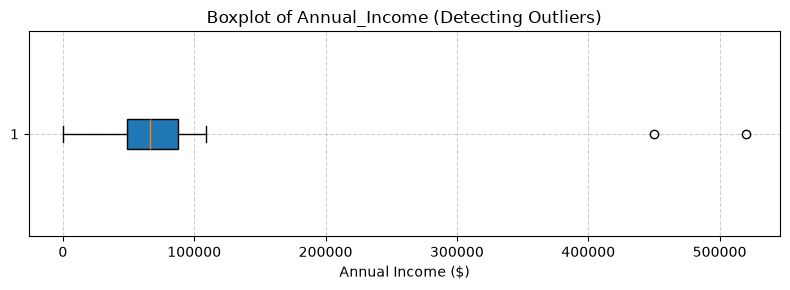

In [24]:
# Visual Inspection: Boxplot of Annual_Income
plt.figure(figsize=(8, 3))
plt.boxplot(df_clean["Annual_Income"], vert=False, patch_artist=True)
plt.title("Boxplot of Annual_Income (Detecting Outliers)")
plt.xlabel("Annual Income ($)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# CRITICAL LAB EXAM LESSON: Detecting an outlier does NOT mean automatically dropping it!
# Incomes like $450,000 and $520,000 are legitimate high earners (affluent executives), NOT data errors.
# Dropping them would discard real customer segments. We keep df_clean intact!


In [25]:
# CHEATSHEET: Section 1 — Outlier Analysis and Removal (OPTIONAL Example)
# If your lab exam explicitly says: "Remove all outliers from the dataset using IQR", use this syntax:
# <df> = <df>[(<df>[<col>] >= lower_bound) & (<df>[<col>] <= upper_bound)]

df_no_outliers = df_clean[(df_clean["Annual_Income"] >= lower_bound) & (df_clean["Annual_Income"] <= upper_bound)].copy()
print(f"Rows before outlier removal: {len(df_clean)}")
print(f"Rows after optional removal: {len(df_no_outliers)}")


Rows before outlier removal: 116
Rows after optional removal: 114


## Section 9 — Final Validation and Export Cleaned CSV

- **When:** At the conclusion of your cleaning pipeline, before saving or proceeding to modeling.
- **Why:** Confirms that no nulls, duplicates, invalid formats, or broken types remain.
- **Cheat sheet:** Section 1 — Pandas / IO (`df.shape`, `df.dtypes`, `df.to_csv(...)`) & Nulls & Masks
- **Code:** Check final health metrics, print a before-vs-after comparison table, and export `loan_applications_cleaned.csv`.


In [26]:
# CHEATSHEET: Section 1 — Pandas / IO & Nulls & Masks
print("=== FINAL DATASET HEALTH CHECK ===")
print("1. Final DataFrame Shape:", df_clean.shape)
print("2. Remaining Null Values across all columns:\n", df_clean.isnull().sum())
print("3. Remaining Duplicate Rows:", df_clean.duplicated().sum())
print("\n4. Final Column Data Types:\n", df_clean.dtypes)
print("\n5. Standardized Target Value Counts:\n", df_clean['Loan_Approved'].value_counts())


=== FINAL DATASET HEALTH CHECK ===
1. Final DataFrame Shape: (116, 9)
2. Remaining Null Values across all columns:
 Application_ID      0
Age                 0
Annual_Income       0
Employment_Type     0
Education           0
Loan_Amount         0
Credit_Score        0
Loan_Approved       0
Application_Date    0
dtype: int64
3. Remaining Duplicate Rows: 0

4. Final Column Data Types:
 Application_ID                 str
Age                        float64
Annual_Income              float64
Employment_Type                str
Education                      str
Loan_Amount                float64
Credit_Score               float64
Loan_Approved                  str
Application_Date    datetime64[us]
dtype: object

5. Standardized Target Value Counts:
 Loan_Approved
Yes    81
No     35
Name: count, dtype: int64


In [27]:
# Before vs After Cleaning Summary Table
summary_data = {
    "Data Quality Check": [
        "Total Rows",
        "Exact Duplicate Rows",
        "Missing Age Values",
        "Missing Annual_Income",
        "Missing Target (Loan_Approved)",
        "Loan_Amount Data Type",
        "Annual_Income Data Type",
        "Target Label Categories",
        "Invalid Ages (<18 or >100)",
        "Invalid Credit Scores (<300 or >850)"
    ],
    "Before (Dirty CSV)": [
        f"{len(df)} rows",
        "2 duplicate rows",
        "4 missing",
        "4 missing",
        "2 missing",
        "object (strings with $, commas)",
        "object (strings with $, commas)",
        "8 variants (yes, Y, no, N, ...)",
        "3 invalid (-28, -5, 150)",
        "2 impossible (950, 120)"
    ],
    "After (Cleaned CSV)": [
        f"{len(df_clean)} rows (valid records)",
        "0 duplicates (dropped)",
        "0 missing (imputed with median)",
        "0 missing (imputed with median)",
        "0 missing (dropped unlabelled rows)",
        "float64 (pure numeric)",
        "float64 (pure numeric)",
        "2 clean categories ('Yes', 'No')",
        "0 invalid (corrected to median)",
        "0 invalid (corrected to median)"
    ]
}
summary_df = pd.DataFrame(summary_data)
display(summary_df)


,Data Quality Check,Before (Dirty CSV),After (Cleaned CSV)
0,Total Rows,118 rows,116 rows (valid records)
1,Exact Duplicate Rows,2 duplicate rows,0 duplicates (dropped)
2,Missing Age Values,4 missing,0 missing (imputed with median)
3,Missing Annual_Income,4 missing,0 missing (imputed with median)
4,Missing Target (Loan_Approved),2 missing,0 missing (dropped unlabelled rows)
5,Loan_Amount Data Type,"object (strings with $, commas)",float64 (pure numeric)
6,Annual_Income Data Type,"object (strings with $, commas)",float64 (pure numeric)
7,Target Label Categories,"8 variants (yes, Y, no, N, ...)","2 clean categories ('Yes', 'No')"
8,Invalid Ages (<18 or >100),"3 invalid (-28, -5, 150)",0 invalid (corrected to median)
9,Invalid Credit Scores (<300 or >850),"2 impossible (950, 120)",0 invalid (corrected to median)


In [28]:
# CHEATSHEET: Section 1 — Pandas / IO
# Save the final cleaned dataset as an actual CSV file
# CHANGE: Set filename as required in exam instructions
cleaned_filename = "loan_applications_cleaned.csv"
df_clean.to_csv(cleaned_filename, index=False)
print(f"Cleaned dataset successfully saved to: {cleaned_filename}")


Cleaned dataset successfully saved to: loan_applications_cleaned.csv


## Section 10 — Basic Preprocessing Preview (Encoders & Scalers)

- **When:** After cleaning is complete, when preparing data for specific ML algorithms.
- **Why:** Machine learning algorithms cannot calculate on raw text (`'Salaried'`, `'Graduate'`) and require numerical scaling for distance/gradient calculations.
- **Cheat sheet:** Section 1 — Scaling & Encoding (`OneHotEncoder`, `OrdinalEncoder`, `StandardScaler`, `MinMaxScaler`, `RobustScaler`)
- **Code:** Demonstrate small, clearly separated examples of encoders and scalers without training any ML models.


In [29]:
# CHEATSHEET: Section 1 — Feature Type Identification / Selection
# Step 1: Identify Numerical vs. Categorical feature subsets
feature_cols = ['Age', 'Annual_Income', 'Loan_Amount', 'Credit_Score', 'Employment_Type', 'Education']
X_sample = df_clean[feature_cols].copy()

num_cols = X_sample.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_sample.select_dtypes(include='object').columns.tolist()

print("Numerical Features:", num_cols)
print("Categorical Features:", cat_cols)


Numerical Features: ['Age', 'Annual_Income', 'Loan_Amount', 'Credit_Score']
Categorical Features: ['Employment_Type', 'Education']


/tmp/ipykernel_91096/3441097314.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_sample.select_dtypes(include='object').columns.tolist()


### 1. OneHotEncoder for Unordered (Nominal) Categories
- **When to use:** For categories with no natural ranking (e.g. `Employment_Type`: Salaried, Self-Employed, Business).
- **Why:** Assigning arbitrary numbers (0, 1, 2) tricks the model into thinking Business > Self-Employed > Salaried! One-hot encoding creates binary 0/1 columns for each category.


In [30]:
# CHEATSHEET: Section 1 — Scaling & Encoding (OneHotEncoder)
# Exact cheatsheet syntax: X_oh = OneHotEncoder(handle_unknown="ignore").fit_transform(X_cat).toarray()
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
emp_encoded = ohe.fit_transform(X_sample[['Employment_Type']])
emp_encoded_df = pd.DataFrame(emp_encoded, columns=ohe.get_feature_names_out(['Employment_Type']))

print("OneHotEncoder applied to Employment_Type:")
display(pd.concat([X_sample[['Employment_Type']].head(4), emp_encoded_df.head(4)], axis=1))


OneHotEncoder applied to Employment_Type:


,Employment_Type,Employment_Type_Business,Employment_Type_Salaried,Employment_Type_Self-Employed
0,Self-Employed,0.0,0.0,1.0
1,Self-Employed,0.0,0.0,1.0
2,Salaried,0.0,1.0,0.0
3,Business,1.0,0.0,0.0


### 2. OrdinalEncoder for Genuinely Ordered (Ordinal) Categories
- **When to use:** When categories have a natural, inherent ranking (e.g. `Education`: High School < Graduate < Post Graduate).
- **Why:** Preserves the ranking order mathematically: High School=0, Graduate=1, Post Graduate=2.


In [31]:
# CHEATSHEET: Section 1 — Scaling & Encoding (OrdinalEncoder)
# Exact cheatsheet syntax: X_ord = OrdinalEncoder(categories=<categories_list>).fit_transform(X_cat)
from sklearn.preprocessing import OrdinalEncoder

edu_ranking = [['High School', 'Graduate', 'Post Graduate']]
ord_enc = OrdinalEncoder(categories=edu_ranking)
edu_encoded = ord_enc.fit_transform(X_sample[['Education']])
edu_encoded_df = pd.DataFrame(edu_encoded, columns=['Education_Rank'])

print("OrdinalEncoder applied to Education (Preserving order):")
display(pd.concat([X_sample[['Education']].head(4), edu_encoded_df.head(4)], axis=1))


OrdinalEncoder applied to Education (Preserving order):


,Education,Education_Rank
0,Graduate,1.0
1,Graduate,1.0
2,Graduate,1.0
3,Graduate,1.0


### 3. Comparison of Scalers: StandardScaler vs. MinMaxScaler vs. RobustScaler
- **StandardScaler:** Centers data to mean = 0 and std = 1. Best for normal (Gaussian) distributions.
- **MinMaxScaler:** Compresses values into [0, 1]. Best when bounded values are needed (e.g. images). Highly sensitive to outliers!
- **RobustScaler:** Uses median and IQR. Best when your dataset has extreme outliers (like income).


In [32]:
# CHEATSHEET: Section 1 — Scaling & Encoding (Scalers Comparison)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

income_data = X_sample[['Annual_Income']].values

# 1. StandardScaler (normal)
X_std = StandardScaler().fit_transform(income_data)

# 2. MinMaxScaler (bounded [0, 1])
X_min = MinMaxScaler().fit_transform(income_data)

# 3. RobustScaler (outlier-resistant)
X_robust = RobustScaler().fit_transform(income_data)

scaler_demo = pd.DataFrame({
    'Raw_Income': income_data.flatten()[:5],
    'StandardScaler': X_std.flatten()[:5],
    'MinMaxScaler': X_min.flatten()[:5],
    'RobustScaler': X_robust.flatten()[:5]
})
print("Side-by-side Scaler Comparison on Annual_Income:")
display(scaler_demo)


Side-by-side Scaler Comparison on Annual_Income:


,Raw_Income,StandardScaler,MinMaxScaler,RobustScaler
0,52000.0,-0.366102,0.100000,-0.371795
1,44000.0,-0.500175,0.084615,-0.576923
2,72000.0,-0.030918,0.138462,0.141026
3,58000.0,-0.265547,0.111538,-0.217949
4,65000.0,-0.148232,0.125000,-0.038462


### Critical Rules for ML Lab Exams:
1. **When is Scaling Required vs Not Required?**
   - **REQUIRED for:** Distance-based models (KNN, K-Means), gradient-based models (Logistic Regression, Linear Regression, Neural Networks), and SVMs. If features are on different scales (e.g., Age 20–60 vs Income $30,000–$100,000), unscaled algorithms let Income dominate simply because of larger numbers.
   - **NOT REQUIRED for:** Tree-based models (Decision Tree, Random Forest, AdaBoost, XGBoost) and Naive Bayes. Trees make orthogonal splits based on ordering thresholds, regardless of feature scale.

2. **Why are Scaling and Encoding Different from Cleaning?**
   - **Cleaning:** Fixes real-world data corruption (missing values, typos, duplicate entries, impossible negative ages).
   - **Preprocessing:** Mathematically reformats already-clean data into geometric vectors suitable for algorithm calculations.

3. **Why must transformations be fitted ONLY on Training Data?**
   - If you fit a scaler or encoder on the entire dataset before splitting, information from the test set (its mean, standard deviation, and range) leaks into the training pipeline.
   - This error is called **Data Leakage**. In a complete ML workflow, always split first:
     ```python
     # Correct ML Workflow:
     # X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
     # scaler.fit(X_train)
     # X_train_scaled = scaler.transform(X_train)
     # X_test_scaled = scaler.transform(X_test)
     ```

---
### End of Data Cleaning Notebook
You are now ready to inspect, clean, and preprocess any tabular CSV dataset in your ML lab exam!
